# 06 · Analysis

**Research question:** can machine learning reconstruct the SPY implied volatility surface more
accurately than SVI, and does any gain hold up in crisis periods?

Test set: every trading day from March 2020 to December 2022 (709 days); three masks per day
(random 20%, wings = outer 10% each side per expiry, one whole expiry). Errors are in
**volatility points** (1 = 0.01 of IV) and computed only on hidden quotes.

In [1]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 160)

In [2]:
import os, glob
from src.stats import compare_to_benchmark
from src.hedging import hedge_errors, hedge_summary

ORDER = ['mean', 'linear', 'svi', 'ssvi', 'xgb', 'xgb_lin', 'xgb_svi', 'gp', 'nn', 'nn_nopen']
LABEL = {'mean': 'Mean (floor)', 'linear': 'B0 Linear', 'svi': 'B1 SVI', 'ssvi': 'B2 SSVI',
         'xgb': 'M1a XGB direct', 'xgb_lin': 'M1b XGB on linear', 'xgb_svi': 'M2 XGB on SVI',
         'gp': 'M3 GP', 'nn': 'M4 NN + penalty', 'nn_nopen': "M4' NN no penalty"}
MODELS = [m for m in ORDER if os.path.exists(f'../results/{m}/scores.csv')]
scores = pd.concat([pd.read_csv(f'../results/{m}/scores.csv', parse_dates=['date'])
                    for m in MODELS], ignore_index=True)
scores = scores[scores['date'] >= '2020-03-01']
print(MODELS)
scores.groupby(['model', 'mask']).size().unstack()

['mean', 'linear', 'svi', 'ssvi', 'xgb', 'xgb_lin', 'xgb_svi', 'gp', 'nn', 'nn_nopen']


mask,expiry,random,wing
model,,,
gp,709,709,709
linear,709,709,709
mean,709,709,709
nn,709,709,709
nn_nopen,709,709,709
ssvi,709,709,709
svi,709,709,709
xgb,709,709,709
xgb_lin,709,709,709


## 1. Main result: accuracy by mask

In [3]:
main = scores.pivot_table(index='model', columns='mask', values='rmse', aggfunc='mean')
main = main.loc[MODELS, ['random', 'expiry', 'wing']].rename(index=LABEL)
main.round(2)

mask,random,expiry,wing
model,,,
Mean (floor),11.67,10.96,20.37
B0 Linear,0.35,0.46,5.16
B1 SVI,0.67,0.86,3.53
B2 SSVI,1.65,1.57,4.12
M1a XGB direct,0.68,0.71,1.60
M1b XGB on linear,0.37,0.50,1.51
M2 XGB on SVI,0.40,0.57,1.25
M3 GP,0.41,0.63,3.26
M4 NN + penalty,0.66,0.68,2.01


Spread across days (5% / median / 95% quantiles of daily RMSE), as in Deep Smoothing.

In [4]:
q = scores.groupby(['model', 'mask'])['rmse'].quantile([0.05, 0.5, 0.95]).unstack()
q.columns = ['q05', 'median', 'q95']
q.unstack('mask').loc[MODELS].rename(index=LABEL).round(2)

q05               median                  q95              
mask              expiry random   wing expiry random   wing expiry random   wing
model                                                                           
Mean (floor)        6.16   8.40  16.08  10.37  11.61  20.12  17.81  15.30  25.61
B0 Linear           0.09   0.18   3.64   0.33   0.30   5.00   1.35   0.68   7.26
B1 SVI              0.28   0.40   2.08   0.69   0.61   3.29   1.68   1.07   5.57
B2 SSVI             0.60   1.20   2.79   1.40   1.60   3.90   3.02   2.24   6.09
M1a XGB direct      0.16   0.27   0.70   0.43   0.42   1.17   1.37   0.93   2.74
M1b XGB on linear   0.11   0.20   0.76   0.40   0.33   1.24   1.19   0.67   2.99
M2 XGB on SVI       0.16   0.20   0.57   0.41   0.31   1.00   1.31   0.75   2.53
M3 GP               0.13   0.23   1.66   0.47   0.37   3.06   1.67   0.72   5.32
M4 NN + penalty     0.29   0.48   1.13   0.56   0.64   1.83   1.49   0.90   3.30
M4' NN no penalty   0.29   0.48   1.10   0.57   0.63   1.77   1.51   0.90   3.31

## 2. Does it hold up in a crisis? Accuracy by market regime

In [5]:
for mask in ['random', 'expiry', 'wing']:
    t = scores[scores['mask'] == mask].pivot_table(index='model', columns='regime',
                                                   values='rmse', aggfunc='mean')
    t = t.loc[MODELS, ['covid_crash', 'recovery', 'calm_2021', 'bear_2022']].rename(index=LABEL)
    print(f'--- {mask} mask: mean daily RMSE (vol points)')
    display(t.round(2))

--- random mask: mean daily RMSE (vol points)


regime,covid_crash,recovery,calm_2021,bear_2022
model,,,,
Mean (floor),16.39,11.95,12.30,10.01
B0 Linear,0.59,0.36,0.26,0.38
B1 SVI,1.23,0.69,0.55,0.68
B2 SSVI,1.88,1.48,1.59,1.78
M1a XGB direct,4.31,0.55,0.39,0.43
M1b XGB on linear,0.80,0.40,0.29,0.35
M2 XGB on SVI,1.35,0.38,0.26,0.39
M3 GP,0.67,0.37,0.34,0.47
M4 NN + penalty,0.95,0.67,0.63,0.63


--- expiry mask: mean daily RMSE (vol points)


regime,covid_crash,recovery,calm_2021,bear_2022
model,,,,
Mean (floor),15.87,11.81,11.30,9.20
B0 Linear,0.77,0.49,0.35,0.50
B1 SVI,1.56,0.88,0.74,0.83
B2 SSVI,1.93,1.58,1.43,1.66
M1a XGB direct,3.92,0.62,0.42,0.51
M1b XGB on linear,1.01,0.56,0.37,0.49
M2 XGB on SVI,1.53,0.55,0.46,0.54
M3 GP,1.04,0.64,0.46,0.74
M4 NN + penalty,1.07,0.76,0.59,0.66


--- wing mask: mean daily RMSE (vol points)


regime,covid_crash,recovery,calm_2021,bear_2022
model,,,,
Mean (floor),24.77,20.03,21.14,19.05
B0 Linear,6.64,5.05,4.94,5.21
B1 SVI,4.36,3.61,2.96,3.92
B2 SSVI,4.32,3.61,3.68,4.86
M1a XGB direct,7.39,1.44,0.97,1.35
M1b XGB on linear,4.12,1.49,1.08,1.50
M2 XGB on SVI,2.99,1.11,0.74,1.56
M3 GP,5.07,3.34,2.73,3.43
M4 NN + penalty,3.51,2.06,1.64,2.08


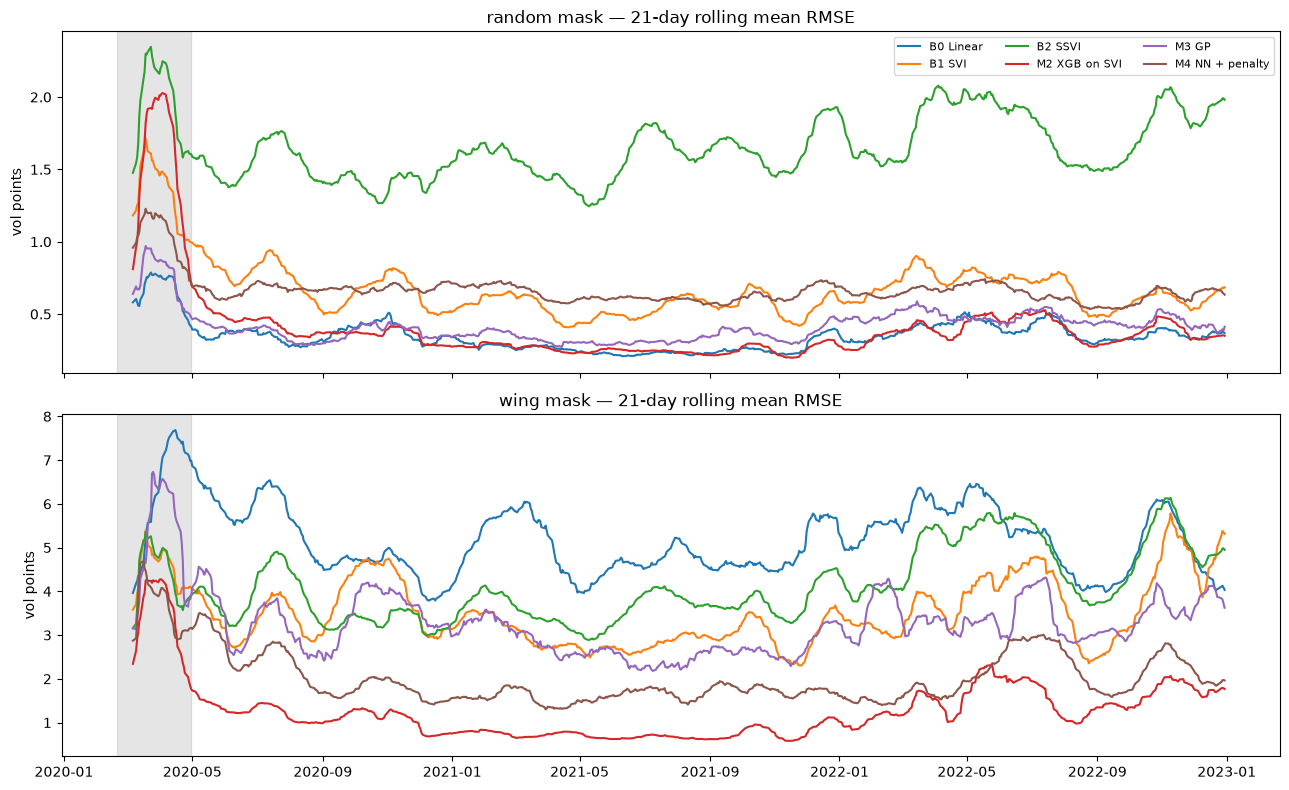

In [6]:
SHOW = [m for m in ['linear', 'svi', 'ssvi', 'xgb_svi', 'gp', 'nn'] if m in MODELS]
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, mask in zip(axes, ['random', 'wing']):
    for m in SHOW:
        s = scores[(scores['model'] == m) & (scores['mask'] == mask)].set_index('date')['rmse']
        ax.plot(s.sort_index().rolling(21, min_periods=5).mean(), label=LABEL[m])
    ax.axvspan(pd.Timestamp('2020-02-20'), pd.Timestamp('2020-04-30'), color='grey', alpha=0.2)
    ax.set_title(f'{mask} mask — 21-day rolling mean RMSE'); ax.set_ylabel('vol points')
axes[0].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

## 3. Is the gain over SVI statistically significant?

Diebold–Mariano test on daily squared errors (Newey–West, 5 lags), and a 95% moving-block
bootstrap interval (10-day blocks) for the % improvement in mean RMSE over SVI.
Positive improvement = better than SVI.

In [7]:
sig = compare_to_benchmark(scores, benchmark='svi')
sig['model'] = sig['model'].map(LABEL)
sig.round({'rmse_model': 2, 'rmse_svi': 2, 'improvement_%': 1, 'ci_low_%': 1, 'ci_high_%': 1,
           'dm_stat': 2, 'p_value': 4, 'win_rate_%': 1})

,mask,model,days,rmse_model,rmse_svi,improvement_%,ci_low_%,ci_high_%,dm_stat,p_value,win_rate_%
0,expiry,B0 Linear,709,0.46,0.86,46.2,39.9,52.6,-1.33,0.1846,87.9
1,expiry,M1b XGB on linear,709,0.50,0.86,41.9,35.6,48.7,-1.32,0.1869,85.5
2,expiry,M2 XGB on SVI,709,0.57,0.86,32.9,26.9,38.3,-1.67,0.0955,86.7
3,expiry,M3 GP,709,0.63,0.86,26.1,17.5,35.7,-1.17,0.2415,73.3
4,expiry,M4 NN + penalty,709,0.68,0.86,20.2,11.7,29.5,-1.19,0.2335,60.4
5,expiry,M4' NN no penalty,709,0.68,0.86,20.1,11.6,29.4,-1.19,0.2341,60.5
6,expiry,M1a XGB direct,709,0.71,0.86,17.2,-14.0,40.0,0.21,0.8348,78.6
7,expiry,B2 SSVI,709,1.57,0.86,-83.7,-105.4,-62.3,0.35,0.7256,9.6
8,expiry,Mean (floor),709,10.96,0.86,-1180.3,-1342.8,-1046.4,21.29,0.0000,0.1
9,random,B0 Linear,709,0.35,0.67,48.5,45.9,50.9,-10.06,0.0000,95.5


## 4. Where on the surface are the errors?

Regional RMSE: rows = standardised moneyness z = k/√T, columns = maturity buckets.

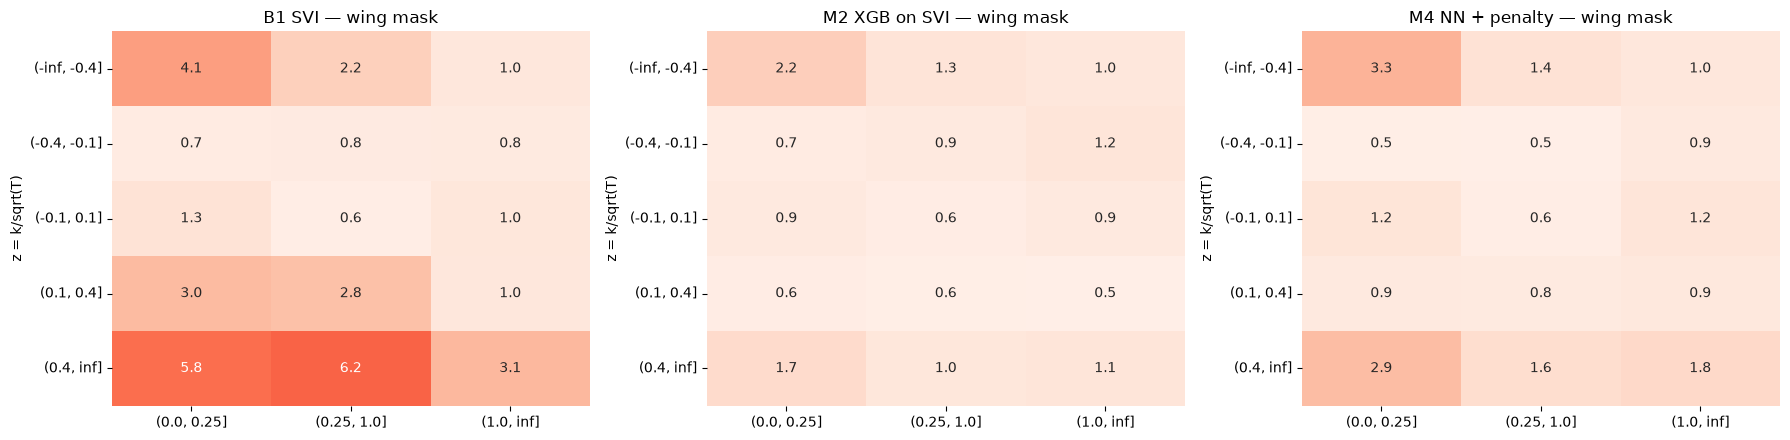

In [8]:
import seaborn as sns
mask = 'wing'
pair = [m for m in ['svi', 'xgb_svi', 'nn'] if m in MODELS]
fig, axes = plt.subplots(1, len(pair), figsize=(6 * len(pair), 4.5))
for ax, m in zip(np.atleast_1d(axes), pair):
    tab = pd.read_csv(f'../results/{m}/regional_{mask}.csv', index_col=0)
    sns.heatmap(tab, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=12, ax=ax, cbar=False)
    ax.set_title(f'{LABEL[m]} — {mask} mask')
plt.tight_layout(); plt.show()

## 5. Accuracy vs no-arbitrage

In [9]:
arb = scores[scores['mask'] == 'random'].groupby('model')[
    ['rmse', 'butterfly_rate', 'calendar_rate', 'butterfly_size', 'calendar_size']].mean()
arb.loc[MODELS].rename(index=LABEL).round(4)

,rmse,butterfly_rate,calendar_rate,butterfly_size,calendar_size
model,,,,,
Mean (floor),11.6697,0.0000,0.0000,0.0000,0.0000
B0 Linear,0.3452,0.1559,0.0192,1.8047,0.0026
B1 SVI,0.6697,0.0110,0.1429,0.0512,0.0046
B2 SSVI,1.6524,0.0000,0.0000,0.0000,0.0000
M1a XGB direct,0.6816,0.2498,0.0575,1.0261,0.0013
M1b XGB on linear,0.3693,0.2149,0.0941,1.2694,0.0021
M2 XGB on SVI,0.3982,0.1633,0.0849,0.6578,0.0025
M3 GP,0.4119,0.0597,0.0492,0.3376,0.0017
M4 NN + penalty,0.6610,0.0059,0.0380,0.1353,0.0002


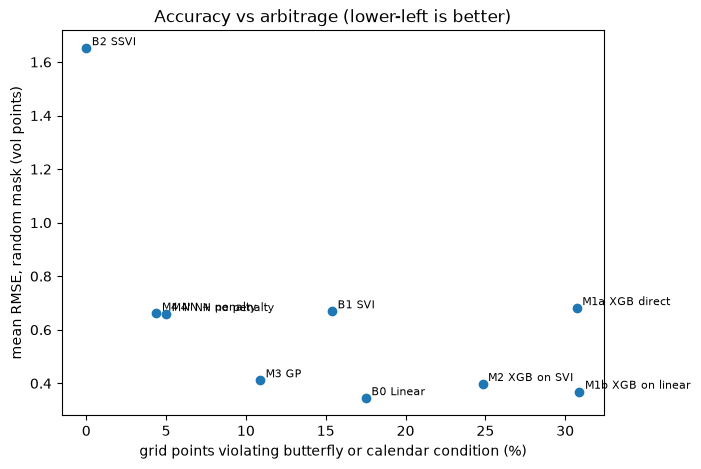

In [10]:
a = arb.loc[[m for m in MODELS if m != 'mean']]
a['any_violation'] = a['butterfly_rate'] + a['calendar_rate']
plt.figure(figsize=(7, 5))
plt.scatter(a['any_violation'] * 100, a['rmse'])
for m, r in a.iterrows():
    plt.annotate(LABEL[m], (r['any_violation'] * 100, r['rmse']), fontsize=8,
                 xytext=(4, 2), textcoords='offset points')
plt.xlabel('grid points violating butterfly or calendar condition (%)')
plt.ylabel('mean RMSE, random mask (vol points)')
plt.title('Accuracy vs arbitrage (lower-left is better)'); plt.show()

## 6. Sparsity: how fast does each model degrade as more quotes are hidden?

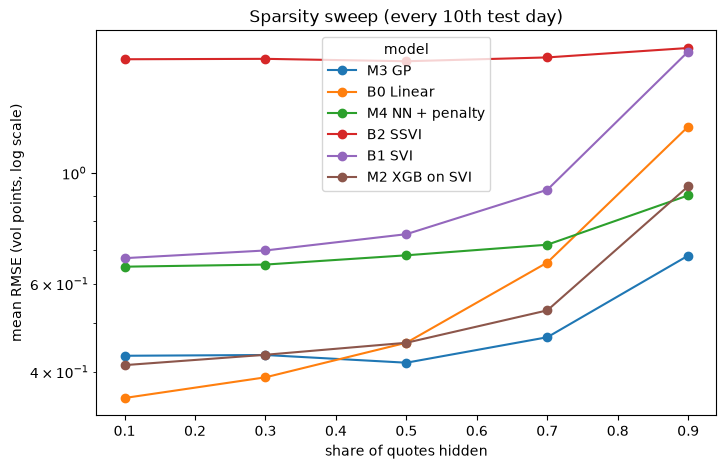

model,M3 GP,B0 Linear,M4 NN + penalty,B2 SSVI,B1 SVI,M2 XGB on SVI
frac,,,,,,
0.1,0.43,0.35,0.65,1.69,0.67,0.41
0.3,0.43,0.39,0.66,1.69,0.70,0.43
0.5,0.42,0.46,0.68,1.67,0.75,0.46
0.7,0.47,0.66,0.72,1.70,0.92,0.53
0.9,0.68,1.24,0.90,1.78,1.75,0.94


In [11]:
sp = pd.read_csv('../results/sparsity.csv')
curve = sp.groupby(['model', 'frac'])['rmse'].mean().unstack('model')
curve.rename(columns=LABEL).plot(marker='o', figsize=(8, 5), logy=True)
plt.xlabel('share of quotes hidden'); plt.ylabel('mean RMSE (vol points, log scale)')
plt.title('Sparsity sweep (every 10th test day)'); plt.show()
curve.rename(columns=LABEL).round(2)

## 7. Hedging: does a better surface give better deltas?
For each hidden option: one-day delta hedge using the model's IV vs using the market's IV.
Error in dollars per option (lower is better).

In [12]:
data = pd.read_parquet('../data/processed/options_features.parquet',
                       columns=['quote_date', 'expire_date', 'strike', 'type', 'mid', 'F',
                                'underlying_last'])
hedge = {}
for m in [m for m in ['linear', 'svi', 'ssvi', 'xgb_svi', 'gp', 'nn'] if m in MODELS]:
    p = pd.read_parquet(f'../results/{m}/preds.parquet')
    hedge[m] = hedge_summary(hedge_errors(p, data))
pd.concat(hedge).rename(index=LABEL).round(4)

n  rmse_model  rmse_true_iv  rmse_unhedged  mean_abs_delta_gap
                mask                                                                         
B0 Linear       expiry   51812.0      0.4393        0.4388         1.1726              0.0019
                random  298852.0      0.4737        0.4737         1.2101              0.0006
                wing    262121.0      0.2381        0.2332         0.3964              0.0033
B1 SVI          expiry   51812.0      0.4430        0.4388         1.1726              0.0040
                random  298852.0      0.4790        0.4737         1.2101              0.0033
                wing    262121.0      0.2385        0.2332         0.3964              0.0063
B2 SSVI         expiry   51812.0      0.4365        0.4388         1.1726              0.0065
                random  298852.0      0.4715        0.4737         1.2101              0.0063
                wing    262121.0      0.2399        0.2332         0.3964              0.0052
M2 XGB on SVI   expiry   51812.0      0.4373        0.4388         1.1726              0.0025
                random  298852.0      0.4731        0.4737         1.2101              0.0015
                wing    262121.0      0.2357        0.2332         0.3964              0.0023
M3 GP           expiry   51812.0      0.4387        0.4388         1.1726              0.0027
                random  298852.0      0.4734        0.4737         1.2101              0.0009
                wing    262121.0      0.2327        0.2332         0.3964              0.0039
M4 NN + penalty expiry   51812.0      0.4400        0.4388         1.1726              0.0035
                random  298852.0      0.4730        0.4737         1.2101              0.0030
                wing    262121.0      0.2363        0.2332         0.3964              0.0034

## 8. A crisis day up close

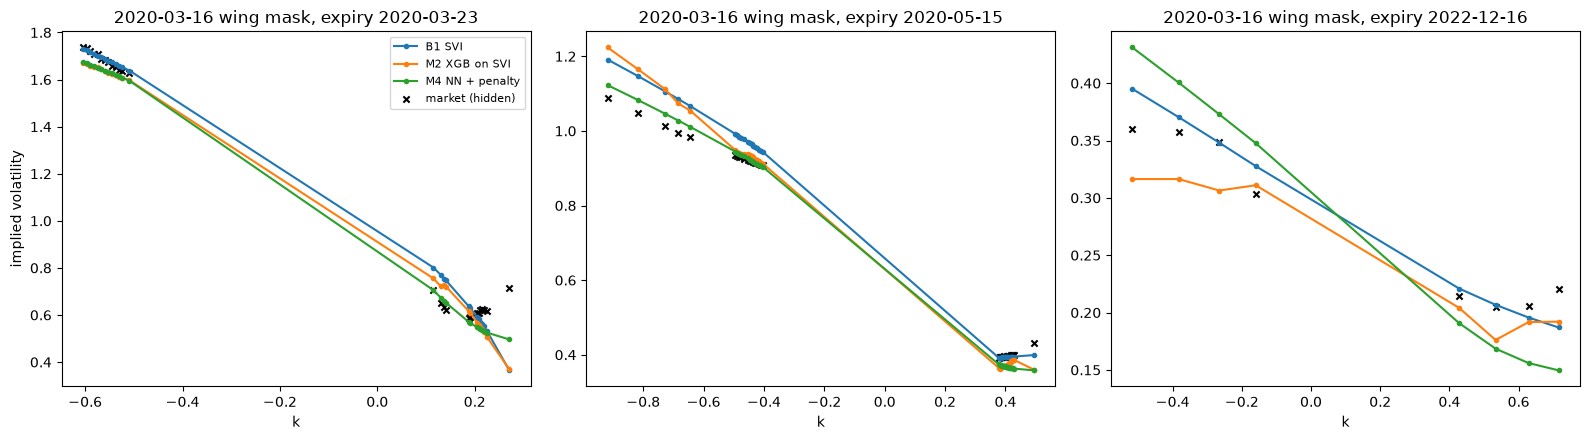

In [13]:
DAY = pd.Timestamp('2020-03-16')
m_show = [m for m in ['svi', 'xgb_svi', 'nn'] if m in MODELS]
preds = {m: pd.read_parquet(f'../results/{m}/preds.parquet',
                            filters=[('date', '==', DAY), ('mask', '==', 'wing')]) for m in m_show}
p0 = preds[m_show[0]]
exp = np.sort(p0['expire_date'].unique())
picks = exp[np.linspace(0, len(exp) - 1, 3).astype(int)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, e in zip(axes, picks):
    for m in m_show:
        q = preds[m][preds[m]['expire_date'] == e].sort_values('k')
        ax.plot(q['k'], q['iv_pred'], 'o-', ms=3, label=LABEL[m])
    q = p0[p0['expire_date'] == e]
    ax.scatter(q['k'], q['iv_true'], c='black', s=20, marker='x', label='market (hidden)')
    ax.set_title(f'{DAY.date()} wing mask, expiry {pd.Timestamp(e).date()}'); ax.set_xlabel('k')
axes[0].set_ylabel('implied volatility'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. Conclusions
*Write the answers here once the numbers above are final:*
1. Which model is most accurate on each mask, and by how much versus SVI (with the CI and p-value)?
2. Does the ranking change in the COVID crash and the 2022 bear market?
3. Which regions (wings, short maturities) drive the errors?
4. Is there an accuracy–arbitrage trade-off (SSVI vs SVI vs NN with/without penalty)?
5. Does better accuracy translate into better hedging?
6. Limitations: American options (late-2022 put/call IV gap), provider IVs, one underlying,
   three turbulent years.